In [10]:
import os
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

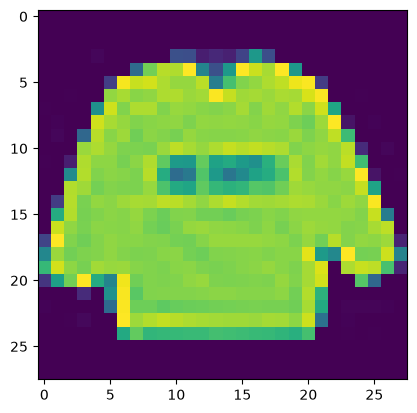

In [11]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

In [12]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:, 0]))

X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(
    X, y, test_size=0.2, random_state=13
)

X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32') / 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32') / 255

# Préparation des données de test
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))

X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32') / 255

In [13]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input, Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

reseauNeurone1Convolution = Sequential()
reseauNeurone1Convolution.add(Input(shape=dimentionImage))
reseauNeurone1Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurone1Convolution.add(Dropout(0.2))
reseauNeurone1Convolution.add(Flatten())
reseauNeurone1Convolution.add(Dense(128, activation='relu'))
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

reseauNeurone1Convolution.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.Adam(),
    metrics=['accuracy']
)

Epoch 1/10


W0000 00:00:1793932586.303052   29753 cpu_allocator_impl.cc:174] Allocation of 150528000 exceeds 10% of free system memory.


188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.8149 - loss: 0.5367 - val_accuracy: 0.8638 - val_loss: 0.3868
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8777 - loss: 0.3481 - val_accuracy: 0.8817 - val_loss: 0.3343
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8910 - loss: 0.3083 - val_accuracy: 0.8887 - val_loss: 0.3123
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.9017 - loss: 0.2795 - val_accuracy: 0.8934 - val_loss: 0.3015
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9077 - loss: 0.2598 - val_accuracy: 0.9003 - val_loss: 0.2828
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.9105 - loss: 0.2473 - val_accuracy: 0.9045 - val_loss: 0.2712
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9161 - loss: 0.2338 - val_accuracy: 0.9042 - val_loss: 0.2652
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9200 - loss: 0.2215 - val_accuracy: 0.902

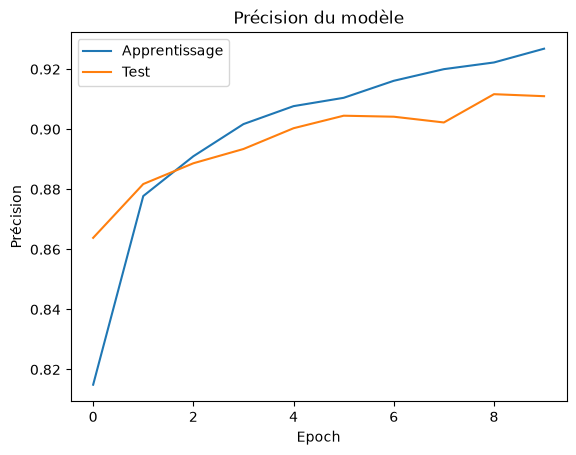

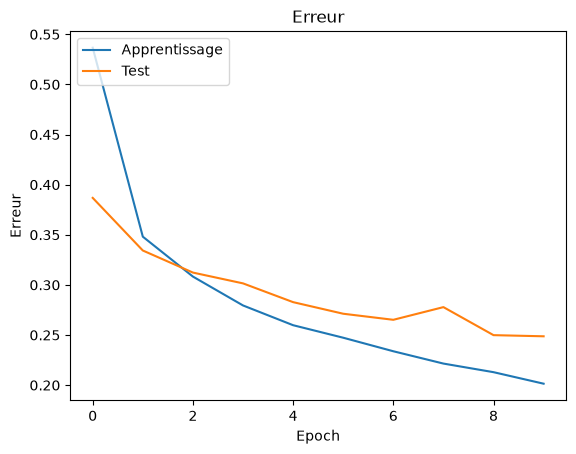

In [14]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage,
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation)
)

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08
)

nouvelles_images_apprentissage = generateur_images.flow(X_apprentissage, y_apprentissage, batch_size=256)
nouvelles_images_validation = generateur_images.flow(X_validation, y_validation, batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000 // 256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000 // 256,
    verbose=1
)

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.8291 - loss: 0.4624 - val_accuracy: 0.8531 - val_loss: 0.4013
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8359 - loss: 0.4615 - val_accuracy: 0.8493 - val_loss: 0.4070
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.8497 - loss: 0.4033 - val_accuracy: 0.8584 - val_loss: 0.3825
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8750 - loss: 0.3451 - val_accuracy: 0.8559 - val_loss: 0.3873
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.8572 - loss: 0.3833 - val_accuracy: 0.8557 - val_loss: 0.3807
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8867 - loss: 0.3489 - val_accuracy: 0.8598 - val_loss: 0.3796
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.8616 - loss: 0.3717 - val_accuracy: 0.8638 - val_loss: 0.3615
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8750 - loss: 0.3325 - val_

In [16]:
os.makedirs("modele", exist_ok=True)

model_json = reseauNeurone1Convolution.to_json()
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
